# ADY201m - AI, DATA SCIENCE WITH PYTHON & SQL
### FINAL REPORT

---

### THÔNG TIN DỰ ÁN
- **Tên dự án:** Dự đoán học lực & Cảnh báo sớm sinh viên có nguy cơ học lại (Student Performance Analytics)
- **Mã lớp:** AI2102
- **Tên nhóm:** Nhóm 6
- **Thành viên nhóm:**
  1. Hoàng Văn Đức - HE210214 - Thành Viên
  2. Phạm Huy Vũ - HE210285 - Thành viên
  3. Nguyễn Tuấn Anh - HE210230 - Thành Viên
  4. Nguyễn Đình An - HE210153 - Thành Viên
- **Nguồn Dataset:** Open University Learning Analytics Dataset (OULAD) – UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/349 (DOI: 10.24432/C5KK69), giấy phép CC-BY 4.0

### 1.1: Bối cảnh bài toán và lý do thực hiện
- **Bối cảnh bài toán:** Ở các trường đại học, việc sinh viên trượt môn hoặc bỏ dở học phần gây thiệt hại cho cả hai phía. Sinh viên mất thêm học phí và thời gian, có nguy cơ chậm tốt nghiệp. Nhà trường thì giảm tỷ lệ tốt nghiệp đúng hạn và tốn thêm nguồn lực mở lớp học lại. Hiện nay việc phát hiện sinh viên gặp khó khăn chủ yếu dựa vào điểm giữa kỳ hoặc cuối kỳ, tức là khi đã quá muộn để can thiệp. Trong khi đó, hệ thống học trực tuyến (LMS/VLE) ghi lại hàng ngày dấu vết hành vi học tập: đăng nhập, truy cập tài liệu, nộp bài. Đây là nguồn dữ liệu có sẵn nhưng chưa được khai thác.
- **Vấn đề chính cần giải quyết:** Xác định những sinh viên có nguy cơ cao sẽ trượt (Fail) hoặc rút khỏi học phần (Withdrawn), tức là có nguy cơ phải học lại **ngay từ khi có được kết quả của các bài kiểm tra chiếm 40-50% trọng số điểm môn học** . Việc dự đoán chỉ dựa trên thông tin nền tảng, lịch sử học lại, hành vi trên VLE và kết quả các bài kiểm tra đầu tiên.
- **Giá trị/ Ý nghĩa đem lại:** Danh sách cảnh báo sớm giúp cố vấn học tập và giảng viên ưu tiên nguồn lực hỗ trợ có hạn (gọi điện, phụ đạo, tư vấn giảm tải) cho đúng người, vào lúc còn đủ thời gian để thay đổi kết quả. Các hệ thống tương tự như Course Signals tại Đại học Purdue (Arnold & Pistilli, 2012) và OU Analyse tại The Open University (Hlosta et al., 2017) đã chứng minh tính khả thi. Dự án dùng bộ dữ liệu OULAD của The Open University (Anh), gồm 32.593 lượt đăng ký học phần của sinh viên đại học.

### 1.2: Các câu hỏi cốt lõi
- **Câu hỏi 1:** Những yếu tố nào quan sát được trước mốc dự đoán dự báo mạnh nhất việc sinh viên trượt hoặc bỏ học phần? Các yếu tố được xem xét gồm mức độ tương tác VLE, kết quả các bài kiểm tra đầu tiên và số lần đã học lại.
- **Câu hỏi 2:** Với nguồn lực tư vấn có hạn, mô hình cần đạt Recall bao nhiêu để phát hiện phần lớn sinh viên có nguy cơ?

### 1.3: Chi tiết bài toán
- **Problem Type:** Học có giám sát (Supervised Learning), phân loại 2 nhóm (Binary Classification).
- **Đơn vị phân tích:** 1 dòng = 1 sinh viên × 1 lớp học phần (`code_module` + `code_presentation`).
- **Thời điểm dự đoán (cut-off):** Sau khi có đủ 40-50% trọng số điểm môn học kể từ khi học phần bắt đầu. Có hai lý do chọn mốc này:
  - Khi đạt được tầm 40-50% trọng số điểm của môn học, đã có ít nhất 2 bài kiểm tra được hoàn thành và khoảng 60 đến 120 ngày học để đánh giá dựa trên điểm số và lượng truy cập vào tài liệu học tập.
  - Khi đó vẫn còn khoảng 45% thời lượng học phần để can thiệp.
- **Target Variable (y):** `at_risk` có hai giá trị:
  - `1` (có nguy cơ học lại): `final_result` là `Fail` hoặc `Withdrawn`.
  - `0` (an toàn): `final_result` là `Pass` hoặc `Distinction`.
- **Expected Feature Variables (X):**
  - Lịch sử học tập: số lần đã học học phần này (`num_of_prev_attempts`).
  - Hành vi VLE đến thời điểm dự đoán: tổng click, số ngày hoạt động, số tài nguyên truy cập, click trước khai giảng.
  - Đánh giá đến thời điểm dự đoán: số bài đến hạn, số bài đã nộp, điểm trung bình, số bài nộp trễ.
  - **Không dùng** các thông tin chỉ có sau mốc cut-off, như ngày rút học phần và điểm các bài sau thời điểm dự đoán, để tránh rò rỉ thông tin tương lai.
- **Evaluation Metric:**
  - Chỉ số chính: **Recall** của lớp `at_risk = 1` và **F1-Score**. Lý do là bỏ sót một sinh viên cần hỗ trợ (False Negative) tốn kém hơn nhiều so với một cuộc gọi tư vấn thừa (False Positive).
  - Chỉ số phụ: **PR-AUC** và **ROC-AUC** để so sánh mô hình độc lập với ngưỡng phân loại.

# PART 2: THU THẬP DỮ LIỆU

### 2.1 Nguồn dữ liệu

| Thuộc tính | Mô tả |
|:---|:---|
| **Tên dataset** | Open University Learning Analytics Dataset (OULAD) |
| **Công bố gốc** | Kuzilek, Hlosta, Zdrahal (2017). *Scientific Data* 4:170171. DOI 10.1038/sdata.2017.171 |
| **Repository** | UCI ML Repository, id 349 (DOI 10.24432/C5KK69) |
| **Giấy phép** | CC-BY 4.0 |
| **Thời gian** | 4 kỳ: 2013B, 2013J, 2014B, 2014J (B=Feb, J=Oct) |
| **Phạm vi** | 32.593 lượt ghi danh × 7 bảng quan hệ |

### 2.2 Lấy dữ liệu từ file

Dữ liệu OULAD gồm **7 bảng CSV** đặt sẵn trong `data/raw/`. Riêng `studentVle.csv` (khoảng 450 MB) được lưu dạng nén `studentVle.csv.gz`; nếu chưa có file CSV thì giải nén ra trước khi đọc.

In [1]:
import gzip, shutil
from pathlib import Path

RAW = Path('data/raw')
TABLES = ['courses', 'assessments', 'vle', 'studentInfo',
          'studentRegistration', 'studentAssessment', 'studentVle']

vle_csv = RAW / 'studentVle.csv'
if not vle_csv.exists():
    with gzip.open(RAW / 'studentVle.csv.gz', 'rb') as src, open(vle_csv, 'wb') as dst:
        shutil.copyfileobj(src, dst)

for t in TABLES:
    print(f'{t + ".csv":26s} {(RAW / f"{t}.csv").stat().st_size / 1e6:8.1f} MB')

courses.csv                     0.0 MB
assessments.csv                 0.0 MB
vle.csv                         0.3 MB
studentInfo.csv                 3.5 MB
studentRegistration.csv         1.1 MB
studentAssessment.csv           5.7 MB
studentVle.csv                453.8 MB


### 2.3 Tích hợp dữ liệu bằng SQL (magic `%%sql`)

Dùng **jupysql** + **DuckDB**: DuckDB đọc thẳng file CSV nên không cần bước nạp dữ liệu vào database. Pipeline gồm 5 bước, mọi đặc trưng chỉ dùng dữ liệu **trước `cutoff_day`** để không nhìn tương lai.

In [2]:
import duckdb
conn = duckdb.connect()
%load_ext sql
%sql conn
%config SqlMagic.displaylimit = 5

**Bước 0.** Khai báo 5 bảng CSV cần dùng dưới dạng view (`?` trong dữ liệu gốc là NULL). `courses` và `vle` không cần cho bài toán.

In [3]:
%%sql
CREATE OR REPLACE VIEW assessments         AS SELECT * FROM read_csv('data/raw/assessments.csv',         nullstr = '?');
CREATE OR REPLACE VIEW studentInfo         AS SELECT * FROM read_csv('data/raw/studentInfo.csv',         nullstr = '?');
CREATE OR REPLACE VIEW studentRegistration AS SELECT * FROM read_csv('data/raw/studentRegistration.csv', nullstr = '?');
CREATE OR REPLACE VIEW studentAssessment   AS SELECT * FROM read_csv('data/raw/studentAssessment.csv',   nullstr = '?');
CREATE OR REPLACE VIEW studentVle          AS SELECT * FROM read_csv('data/raw/studentVle.csv',          nullstr = '?');

Running query in 'DuckDBPyConnection'

Count


**Bước 1 — `module_cutoff`.** Sắp các bài kiểm tra theo ngày đến hạn, cộng dồn trọng số. `cutoff_day` là ngày đầu tiên tổng trọng số đạt ≥ 40%. Cutoff tính riêng cho từng lớp vì mỗi môn có lịch kiểm tra khác nhau.

In [4]:
%%sql
CREATE OR REPLACE TABLE module_cutoff AS
SELECT code_module, code_presentation, MIN(date) AS cutoff_day
FROM (
    SELECT *, SUM(weight) OVER (PARTITION BY code_module, code_presentation
                                ORDER BY date ROWS UNBOUNDED PRECEDING) AS cum_weight
    FROM assessments
    WHERE date IS NOT NULL AND weight > 0
)
WHERE cum_weight >= 40
GROUP BY code_module, code_presentation;

SELECT code_module, MIN(cutoff_day) AS min_cutoff, MAX(cutoff_day) AS max_cutoff
FROM module_cutoff GROUP BY code_module ORDER BY code_module;

Running query in 'DuckDBPyConnection'

22 rows affected.

code_module,min_cutoff,max_cutoff
AAA,117,117
BBB,82,152
CCC,102,109
DDD,74,114
EEE,68,68


**Bước 2 — `assess_due`.** Các bài kiểm tra (trọng số > 0) đến hạn trước cutoff.

In [5]:
%%sql
CREATE OR REPLACE TABLE assess_due AS
SELECT a.*
FROM assessments a
JOIN module_cutoff c USING (code_module, code_presentation)
WHERE a.date < c.cutoff_day AND a.weight > 0;

Running query in 'DuckDBPyConnection'

45 rows affected.

Count
45


**Bước 3 — `vle_agg`.** Tổng hợp click VLE của mỗi sinh viên trước cutoff. Click có `date < 0` là click trước ngày khai giảng.

In [6]:
%%sql
CREATE OR REPLACE TABLE vle_agg AS
SELECT v.code_module, v.code_presentation, v.id_student,
       SUM(v.sum_click)                                      AS total_clicks,
       COUNT(DISTINCT v.date)                                AS active_days,
       COUNT(DISTINCT v.id_site)                             AS n_resources,
       SUM(CASE WHEN v.date < 0 THEN v.sum_click ELSE 0 END) AS clicks_before_start
FROM studentVle v
JOIN module_cutoff c USING (code_module, code_presentation)
WHERE v.date < c.cutoff_day
GROUP BY ALL;

Running query in 'DuckDBPyConnection'

29184 rows affected.

Count
29184


**Bước 4 — `assess_agg`.** Số bài đã nộp, điểm trung bình và số bài nộp trễ của mỗi sinh viên trước cutoff.

In [7]:
%%sql
CREATE OR REPLACE TABLE assess_agg AS
SELECT d.code_module, d.code_presentation, s.id_student,
       COUNT(*)                                                   AS n_submitted,
       AVG(s.score)                                               AS avg_score,
       SUM(CASE WHEN s.date_submitted > d.date THEN 1 ELSE 0 END) AS n_late
FROM studentAssessment s
JOIN assess_due d    USING (id_assessment)
JOIN module_cutoff c USING (code_module, code_presentation)
WHERE s.date_submitted < c.cutoff_day
GROUP BY ALL;

Running query in 'DuckDBPyConnection'

23455 rows affected.

Count
23455


**Bước 5 — `df_raw`.** Ghép tất cả theo `(code_module, code_presentation, id_student)`:
- `LEFT JOIN` để giữ sinh viên không click / không nộp bài nào: đây là nhóm nguy cơ cao nhất, `INNER JOIN` sẽ xoá họ.
- Bỏ biến nhân khẩu học (lý do công bằng).
- Giữ nguyên `date_unregistration` và toàn bộ sinh viên. Việc xử lý rò rỉ dữ liệu (data leakage) được làm ở phần 3.2.

In [8]:
%%sql
CREATE OR REPLACE TABLE df_raw AS
SELECT si.code_module, si.code_presentation, si.id_student,
       si.num_of_prev_attempts, si.studied_credits, sr.date_registration,
       sr.date_unregistration, c.cutoff_day,
       COALESCE(v.total_clicks, 0)        AS total_clicks,
       COALESCE(v.active_days, 0)         AS active_days,
       COALESCE(v.n_resources, 0)         AS n_resources,
       COALESCE(v.clicks_before_start, 0) AS clicks_before_start,
       (SELECT COUNT(*) FROM assess_due d
         WHERE d.code_module = si.code_module
           AND d.code_presentation = si.code_presentation) AS n_assess_due,
       COALESCE(a.n_submitted, 0)         AS n_submitted,
       a.avg_score,
       COALESCE(a.n_late, 0)              AS n_late,
       si.final_result,
       CASE WHEN si.final_result IN ('Fail', 'Withdrawn') THEN 1 ELSE 0 END AS at_risk
FROM studentInfo si
JOIN studentRegistration sr USING (code_module, code_presentation, id_student)
JOIN module_cutoff c        USING (code_module, code_presentation)
LEFT JOIN vle_agg v         USING (code_module, code_presentation, id_student)
LEFT JOIN assess_agg a      USING (code_module, code_presentation, id_student)
ORDER BY si.code_module, si.code_presentation, si.id_student;

SELECT COUNT(*) AS n_rows, ROUND(AVG(at_risk), 3) AS at_risk_rate FROM df_raw;

Running query in 'DuckDBPyConnection'

32593 rows affected.

n_rows,at_risk_rate
32593,0.528


Xuất bảng tích hợp ra CSV để kiểm chứng và dùng cho các phần sau.

In [9]:
%%sql
COPY df_raw TO 'data/integrated/Intergrated_data.csv' (HEADER);

Running query in 'DuckDBPyConnection'

32593 rows affected.

Count
32593


**Nhận xét.** `cutoff_day` khác nhau rõ giữa các môn (EEE khoảng 68 ngày, AAA khoảng 117 ngày) nên không dùng được một ngày cố định. Bảng tích hợp có **32.593 dòng × 18 cột** (giữ toàn bộ lượt ghi danh), at_risk khoảng 53%. Các dòng gây rò rỉ dữ liệu được loại ở phần 3.2.

# PART 3: LÀM SẠCH & TIỀN XỬ LÝ

### 3.1 Từ điển dữ liệu (Data Dictionary)

**7 bảng gốc (phần 2.2):**

| Bảng | Số dòng | Khoá | Nội dung chính |
|:---|---:|:---|:---|
| `courses` | 22 | `(module, presentation)` | Danh sách lớp + độ dài kỳ (ngày) |
| `assessments` | 206 | `id_assessment` | Loại bài (TMA/CMA/Exam), ngày đến hạn, trọng số % |
| `vle` | 6.364 | `id_site` | Tài nguyên học + activity_type |
| `studentInfo` | 32.593 | `(module, pres, id_student)` | **Thông tin SV + `final_result`** |
| `studentRegistration` | 32.593 | như trên | `date_registration`, `date_unregistration` |
| `studentAssessment` | 173.912 | `(id_assessment, id_student)` | `score` + `date_submitted` |
| `studentVle` | **10.655.280** | long format | Log click hằng ngày: `(id_site, date, sum_click)` |

Cột `date` trong mọi bảng là **số ngày tính từ ngày khai giảng** (date < 0 = trước khai giảng).

**Bảng tích hợp (phần 2.3):** sinh tự động từ dữ liệu và xuất ra `data/integrated/data_dictionary.csv`.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
RNG = 42

df = pd.read_csv('data/integrated/Intergrated_data.csv')

meaning = {
    'code_module':          'Mã môn học',
    'code_presentation':    'Kỳ học (năm + B=tháng 2 / J=tháng 10)',
    'id_student':           'Mã sinh viên',
    'num_of_prev_attempts': 'Số lần đã học môn này trước đó',
    'studied_credits':      'Tổng số tín chỉ đang học',
    'date_registration':    'Ngày đăng ký so với ngày khai giảng',
    'date_unregistration':  'Ngày huỷ đăng ký (thông tin tương lai, loại ở 3.2)',
    'cutoff_day':           'Ngày cảnh báo (tích luỹ >= 40% trọng số)',
    'total_clicks':         'Tổng click VLE trước cutoff',
    'active_days':          'Số ngày có hoạt động VLE trước cutoff',
    'n_resources':          'Số tài nguyên VLE khác nhau đã truy cập',
    'clicks_before_start':  'Click VLE trước ngày khai giảng',
    'n_assess_due':         'Số bài kiểm tra đến hạn trước cutoff',
    'n_submitted':          'Số bài đã nộp trước cutoff',
    'avg_score':            'Điểm trung bình các bài đã nộp',
    'n_late':               'Số bài nộp trễ',
    'final_result':         'Kết quả cuối kỳ (chỉ dùng để tạo target)',
    'at_risk':              'Target: 1 = Fail/Withdrawn, 0 = Pass/Distinction',
}
data_dict = pd.DataFrame({
    'dtype':     df.dtypes.astype(str),
    'n_missing': df.isna().sum(),
    'n_unique':  df.nunique(),
    'example':   df.iloc[0],
    'meaning':   pd.Series(meaning),
})
data_dict.to_csv('data/integrated/data_dictionary.csv', index_label='column')
print(df.shape)
data_dict

(32593, 18)


,dtype,n_missing,n_unique,example,meaning
code_module,str,0,7,AAA,Mã môn học
code_presentation,str,0,4,2013J,Kỳ học (năm + B=tháng 2 / J=tháng 10)
id_student,int64,0,28785,11391,Mã sinh viên
num_of_prev_attempts,int64,0,7,0,Số lần đã học môn này trước đó
studied_credits,int64,0,61,240,Tổng số tín chỉ đang học
date_registration,float64,45,332,-159.0,Ngày đăng ký so với ngày khai giảng
date_unregistration,float64,22521,416,NaN,"Ngày huỷ đăng ký (thông tin tương lai, loại ở ..."
cutoff_day,int64,0,16,117,Ngày cảnh báo (tích luỹ >= 40% trọng số)
total_clicks,int64,0,3308,628,Tổng click VLE trước cutoff
active_days,int64,0,162,26,Số ngày có hoạt động VLE trước cutoff


### 3.2 Xử lý rò rỉ dữ liệu (Data Leakage) bằng SQL

Bảng tích hợp vẫn chứa thông tin chỉ có **sau** mốc dự đoán `cutoff_day`. Nếu giữ lại, mô hình sẽ "nhìn thấy tương lai" và cho kết quả tốt giả tạo. Bước này làm bằng `%%sql` trên DuckDB, đọc thẳng file `Intergrated_data.csv`:

| Vấn đề | Vì sao là rò rỉ / sai phạm vi | Xử lý |
|---|---|---|
| `date_unregistration` | Ngày rút học phần chỉ biết được sau khi sự việc xảy ra; rút học phần gần như đồng nghĩa với `Withdrawn`. | Bỏ cột (`EXCLUDE`). |
| Sinh viên rút **trước hoặc đúng** `cutoff_day` | Tại mốc dự đoán đã biết họ bỏ học, nhãn là hiển nhiên và không còn can thiệp được. | Loại dòng. |
| Sinh viên đăng ký **sau** `cutoff_day` | Tại mốc dự đoán họ chưa có trong lớp, không có dữ liệu hành vi. | Loại dòng. |

Các đặc trưng VLE và điểm đã được tính chỉ từ dữ liệu trước `cutoff_day` ngay ở phần 2.3, nên không cần xử lý thêm.

In [11]:
%%sql
CREATE OR REPLACE TABLE df_noleak AS
SELECT * EXCLUDE (date_unregistration)
FROM read_csv('data/integrated/Intergrated_data.csv')
WHERE (date_unregistration IS NULL OR date_unregistration > cutoff_day)
  AND (date_registration   IS NULL OR date_registration  <= cutoff_day);

SELECT COUNT(*)                                                   AS n_truoc,
       COUNT(*) FILTER (WHERE date_unregistration <= cutoff_day) AS rut_truoc_cutoff,
       COUNT(*) FILTER (WHERE date_registration   >  cutoff_day) AS dang_ky_sau_cutoff,
       (SELECT COUNT(*) FROM df_noleak)                           AS n_sau,
       (SELECT ROUND(AVG(at_risk), 3) FROM df_noleak)             AS at_risk_rate
FROM read_csv('data/integrated/Intergrated_data.csv');

Running query in 'DuckDBPyConnection'

25219 rows affected.

n_truoc,rut_truoc_cutoff,dang_ky_sau_cutoff,n_sau,at_risk_rate
32593,7368,6,25219,0.39


**Nhận xét.** Từ 32.593 dòng của bảng tích hợp, loại **7.368** sinh viên đã rút trước cutoff và **6** sinh viên đăng ký sau cutoff, còn **25.219 dòng × 17 cột**. Tỷ lệ at_risk giảm từ khoảng 53% xuống 39%: phần lớn nhóm bị loại là `Withdrawn`, nếu giữ lại mô hình sẽ học được một quy luật hiển nhiên thay vì tín hiệu cảnh báo sớm thật sự.

### 3.3 Xử lý giá trị thiếu (Missing Values)

Tiếp tục làm bằng `%%sql` trên bảng `df_noleak`. Chỉ 2 cột có missing, mỗi cột có nguyên nhân riêng nên xử lý riêng:

| Cột | Nguyên nhân | Xử lý |
|---|---|---|
| `date_registration` (7 dòng) | Lỗi nhập liệu | Điền median theo lớp `(code_module, code_presentation)` vì mỗi lớp có cửa sổ đăng ký riêng. |
| `avg_score` (3.722 dòng) | Sinh viên chưa nộp bài nào (`n_submitted = 0`) | Điền **0** và tạo 2 biến cờ để mô hình phân biệt hai tình huống (bên dưới). |
| `avg_score` (8 dòng) | Đã nộp nhưng chưa được chấm | Điền median theo lớp. |

Hai biến cờ (flag, 0/1):
- `dropout_no_activity`: không nộp bài **và** không click VLE, tức đã bỏ học hẳn.
- `active_but_no_submission`: không nộp bài **nhưng** vẫn vào VLE, tức đang trì hoãn.

Median theo lớp được tính bằng hàm cửa sổ `MEDIAN(...) OVER (PARTITION BY code_module, code_presentation)`. Sau bước này nạp bảng kết quả về pandas để làm tiếp.

In [12]:
%%sql
SELECT COUNT(*) - COUNT(date_registration)                         AS date_registration_null,
       COUNT(*) FILTER (WHERE avg_score IS NULL AND n_submitted = 0) AS avg_score_null_chua_nop,
       COUNT(*) FILTER (WHERE avg_score IS NULL AND n_submitted > 0) AS avg_score_null_chua_cham
FROM df_noleak;

Running query in 'DuckDBPyConnection'

date_registration_null,avg_score_null_chua_nop,avg_score_null_chua_cham
7,3722,8


In [13]:
%%sql
CREATE OR REPLACE TABLE df_filled AS
WITH s AS (
    -- chưa nộp bài nào: điểm = 0
    SELECT * REPLACE (CASE WHEN n_submitted = 0 THEN 0 ELSE avg_score END AS avg_score)
    FROM df_noleak
)
SELECT * REPLACE (
           COALESCE(date_registration, MEDIAN(date_registration) OVER w) AS date_registration,
           COALESCE(avg_score,         MEDIAN(avg_score)         OVER w) AS avg_score),
       CASE WHEN n_submitted = 0 AND total_clicks = 0 THEN 1 ELSE 0 END AS dropout_no_activity,
       CASE WHEN n_submitted = 0 AND total_clicks > 0 THEN 1 ELSE 0 END AS active_but_no_submission
FROM s
WINDOW w AS (PARTITION BY code_module, code_presentation)
ORDER BY code_module, code_presentation, id_student;

SELECT 'dropout_no_activity' AS co, dropout_no_activity AS gia_tri, COUNT(*) AS n, ROUND(AVG(at_risk), 3) AS at_risk_rate
FROM df_filled GROUP BY ALL
UNION ALL
SELECT 'active_but_no_submission', active_but_no_submission, COUNT(*), ROUND(AVG(at_risk), 3)
FROM df_filled GROUP BY ALL
ORDER BY co, gia_tri;

Running query in 'DuckDBPyConnection'

25219 rows affected.

co,gia_tri,n,at_risk_rate
active_but_no_submission,0,21908,0.368
active_but_no_submission,1,3311,0.537
dropout_no_activity,0,24808,0.38
dropout_no_activity,1,411,0.993


In [14]:
# Nạp kết quả SQL về pandas để làm tiếp các bước sau
df = conn.sql('SELECT * FROM df_filled').df()
print('Shape:', df.shape, '| Còn missing:', df.isna().sum().sum())

Shape: (25219, 19) | Còn missing: 0


**Nhận xét.** Nhóm `dropout_no_activity = 1` (411 SV) có tỷ lệ nguy cơ khoảng **99%**, nhóm `active_but_no_submission = 1` (3.311 SV) khoảng **54%**, đều cao hơn hẳn mức trung bình 39%. Hai nhóm có mức rủi ro khác nhau nên tách thành 2 cờ là hợp lý.

### 3.4 Xử lý dữ liệu trùng lặp (Duplicates)

Kiểm tra trùng toàn bộ dòng và trùng theo đơn vị phân tích `(code_module, code_presentation, id_student)`. Nếu có trùng theo đơn vị phân tích thì phép JOIN trong SQL bị sai.

In [15]:
key = ['code_module', 'code_presentation', 'id_student']
print('Trùng toàn bộ dòng       :', df.duplicated().sum())
print('Trùng theo đơn vị phân tích:', df.duplicated(subset=key).sum())
df = df.drop_duplicates(subset=key)
print('Shape:', df.shape)

Trùng toàn bộ dòng       : 0
Trùng theo đơn vị phân tích: 0
Shape: (25219, 19)


**Nhận xét.** Không có dòng trùng, phép JOIN trong SQL đúng: mỗi sinh viên chỉ xuất hiện một lần trong mỗi lớp học phần.

### 3.5 Chuẩn hoá dữ liệu

- `id_student` là mã định danh nên chuyển sang chuỗi.
- `code_module`, `final_result` là biến phân loại nên chuyển sang `category`.
- Tách `code_presentation` thành `pres_year` và `pres_semester` (B = Feb, J = Oct).
- Ép kiểu số theo miền giá trị để giảm bộ nhớ: đếm nhỏ (≤ 6) dùng `int8`, các cột đến vài nghìn dùng `int16` (`n_resources` tới 313 và `pres_year` 2013–2014 vượt `int8`), `total_clicks` dùng `int32`, `avg_score` dùng `float16`, các cột 0/1 dùng `bool`.

Sau bước này xuất `data/cleaned/cleaned_dataset.csv`.

In [16]:
df['id_student']    = df['id_student'].astype(str)
df['pres_year']     = df['code_presentation'].str[:4].astype('int16')
df['pres_semester'] = df['code_presentation'].str[-1].map({'B': 'Feb', 'J': 'Oct'})
for c in ['code_module', 'pres_semester', 'final_result']:
    df[c] = df[c].astype('category')

# Ép kiểu gọn theo miền giá trị thực tế
df = df.astype({
    'num_of_prev_attempts': 'int8',  'studied_credits': 'int16', 'date_registration': 'int16',
    'cutoff_day': 'int16',           'total_clicks': 'int32',    'active_days': 'int16',
    'n_resources': 'int16',          'clicks_before_start': 'int16',
    'n_assess_due': 'int8',          'n_submitted': 'int8',      'avg_score': 'float16',
    'n_late': 'int8',                'at_risk': 'bool',
    'dropout_no_activity': 'bool',   'active_but_no_submission': 'bool',
})

df.to_csv('data/cleaned/cleaned_dataset.csv', index=False)
df.dtypes

code_module                 category
code_presentation                str
id_student                       str
num_of_prev_attempts            int8
studied_credits                int16
date_registration              int16
cutoff_day                     int16
total_clicks                   int32
active_days                    int16
n_resources                    int16
clicks_before_start            int16
n_assess_due                    int8
n_submitted                     int8
avg_score                    float16
n_late                          int8
final_result                category
at_risk                         bool
dropout_no_activity             bool
active_but_no_submission        bool
pres_year                      int16
pres_semester               category
dtype: object

### 3.6 Phát hiện và xử lý outlier (Boxplot)

Boxplot theo nhóm `at_risk` cho các biến hành vi. Điểm nằm ngoài râu là outlier theo quy tắc IQR: ngoài khoảng $[Q_1 - 1.5\,IQR,\ Q_3 + 1.5\,IQR]$.

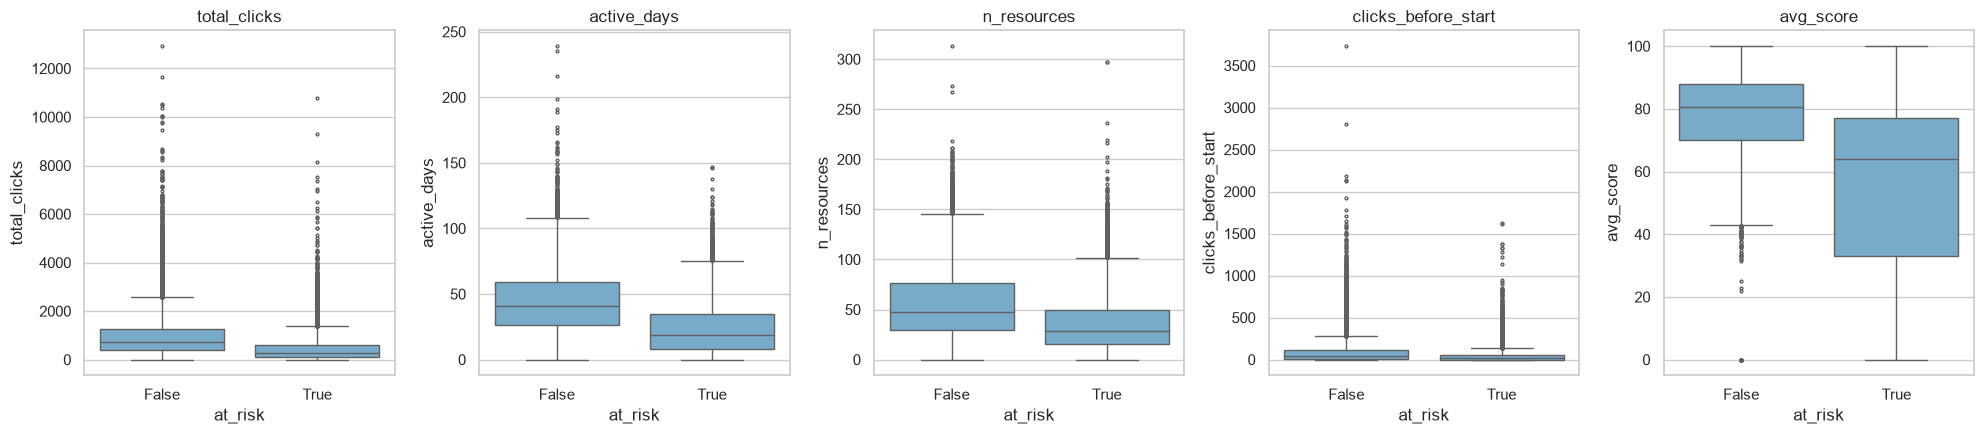

total_clicks           1619
active_days             435
n_resources             723
clicks_before_start    2230
avg_score              3813
Name: n_outlier_IQR, dtype: int64

In [17]:
box = ['total_clicks', 'active_days', 'n_resources', 'clicks_before_start', 'avg_score']
fig, axes = plt.subplots(1, len(box), figsize=(4 * len(box), 4.5))
for ax, c in zip(axes, box):
    sns.boxplot(data=df, x='at_risk', y=c, ax=ax, color='#6BAED6', fliersize=2)
    ax.set_title(c)
plt.tight_layout(); plt.show()

q1, q3 = df[box].quantile(.25), df[box].quantile(.75)
iqr = q3 - q1
((df[box] < q1 - 1.5 * iqr) | (df[box] > q3 + 1.5 * iqr)).sum().rename('n_outlier_IQR')

**Nhận xét.**
- Ở mọi biến hoạt động VLE, hộp của nhóm nguy cơ nằm thấp hơn hẳn nhóm an toàn.
- Outlier của các biến click đều nằm ở đuôi phải: đó là sinh viên rất chăm, không phải lỗi dữ liệu. Nếu xoá theo IQR sẽ mất hàng nghìn dòng mang tín hiệu tốt, nên sẽ xử lý bằng cách **chặn tại phân vị 99** hoặc nén bằng `log` (bên dưới).
- `avg_score` có outlier ở phía dưới (điểm thấp) và đó chính là tín hiệu nguy cơ, nên giữ nguyên.

**Xử lý outlier.**

Từ boxplot ở trên: outlier là sinh viên rất chăm, không phải lỗi dữ liệu, nên **giữ nguyên dòng** và chỉ nén đuôi phải thay vì xoá:

| Biến | Vấn đề | Xử lý |
|---|---|---|
| `total_clicks`, `clicks_before_start` | Lệch phải rất mạnh, nhiều sinh viên có 0 click | Biến đổi `log(1 + x)` thành `log_total_clicks`, `log_clicks_before_start`. Dùng `log(1+x)` để xử lý được giá trị 0. |
| `active_days`, `n_resources` | Đuôi phải dài nhưng lệch vừa phải | **Chặn tại phân vị 99 (P99)**: giá trị lớn hơn P99 được gán bằng P99. |
| `avg_score` | Outlier ở phía điểm thấp | Giữ nguyên vì điểm thấp chính là tín hiệu nguy cơ. |

In [18]:
fe = df.copy()
fe['log_total_clicks']        = np.log1p(fe['total_clicks'])
fe['log_clicks_before_start'] = np.log1p(fe['clicks_before_start'])

CAP = ['active_days', 'n_resources']
p99 = fe[CAP].quantile(.99)
print('Số dòng bị chặn tại P99:', (fe[CAP] > p99).sum().to_dict())
fe[CAP] = fe[CAP].clip(upper=p99, axis=1)

# Độ lệch (skew) trước và sau xử lý
before = ['total_clicks', 'clicks_before_start', 'active_days', 'n_resources']
after  = ['log_total_clicks', 'log_clicks_before_start', 'active_days', 'n_resources']
pd.DataFrame({'skew_truoc': df[before].skew().values,
              'skew_sau':   fe[after].skew().values,
              'max_sau':    fe[after].max().values}, index=after).round(2)

Số dòng bị chặn tại P99: {'active_days': 234, 'n_resources': 251}


,skew_truoc,skew_sau,max_sau
log_total_clicks,3.16,-1.77,9.47
log_clicks_before_start,5.21,-0.28,8.22
active_days,0.93,0.74,108.00
n_resources,1.16,0.98,149.00


**Nhận xét.**
- Log giảm mạnh độ lệch: `total_clicks` từ 3,16 xuống −1,77 (lệch trái nhẹ do cụm sinh viên 0 click), `clicks_before_start` từ 5,21 xuống −0,28.
- Chặn P99 chỉ chạm tới 234 dòng (`active_days`, max còn 108) và 251 dòng (`n_resources`, max còn 149), khoảng 1% dữ liệu. Không dòng nào bị xoá.

# PART 4: EDA & FEATURE ENGINEERING

### 4.1 Phân tích đơn biến

Xem phân bố của target và 4 biến hành vi chính. **Skew** (độ lệch) ghi ở tiêu đề: dương = đuôi dài bên phải.

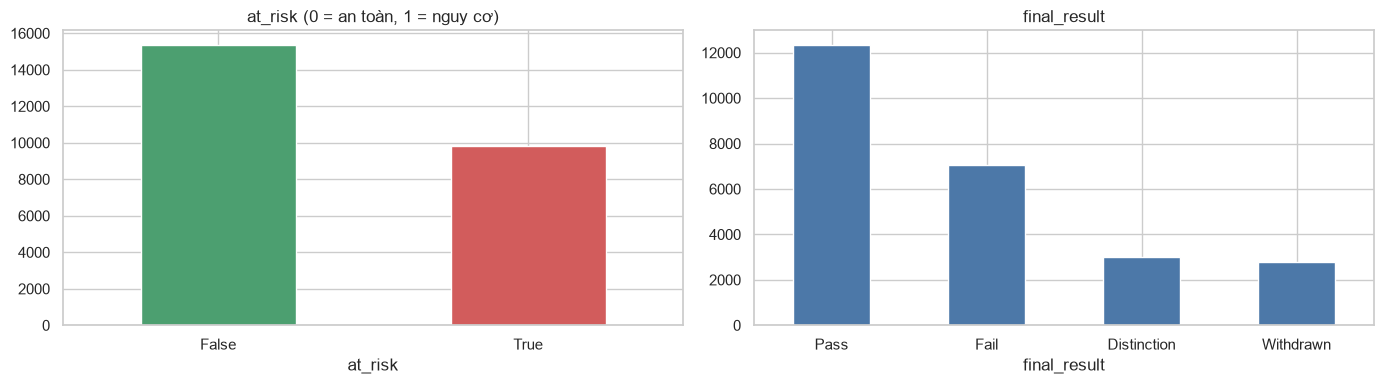

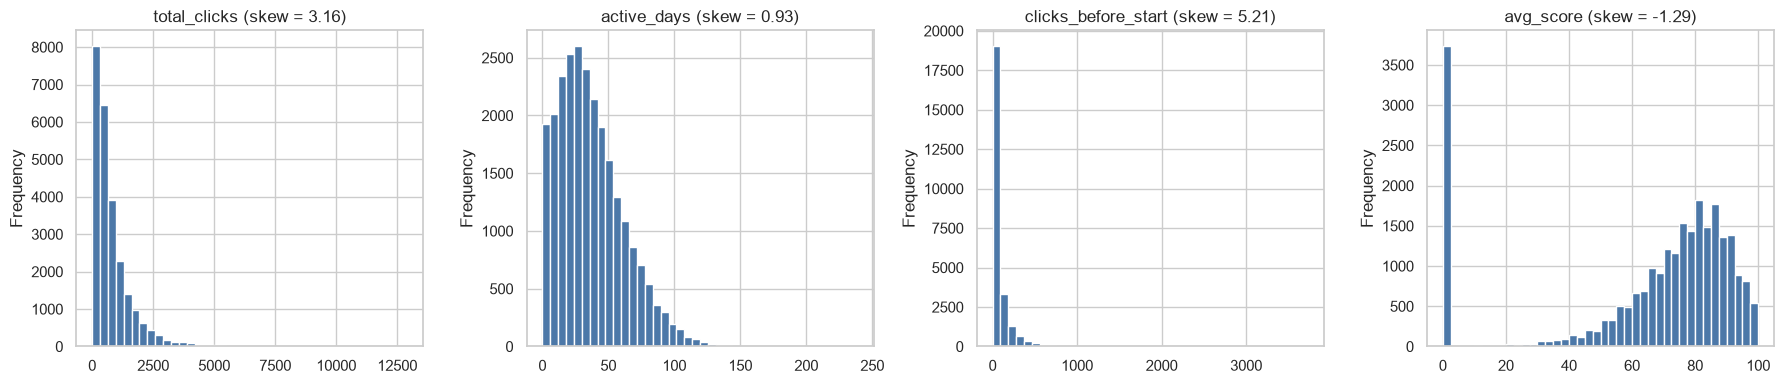

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['at_risk'].value_counts().sort_index().plot.bar(ax=axes[0], color=['#4C9F70', '#D25C5C'], rot=0)
axes[0].set_title('at_risk (0 = an toàn, 1 = nguy cơ)')
df['final_result'].value_counts().plot.bar(ax=axes[1], color='#4C78A8', rot=0)
axes[1].set_title('final_result')
plt.tight_layout(); plt.show()

uni = ['total_clicks', 'active_days', 'clicks_before_start', 'avg_score']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, uni):
    df[c].plot.hist(bins=40, ax=ax, color='#4C78A8')
    ax.set_title(f'{c} (skew = {df[c].skew():.2f})')
plt.tight_layout(); plt.show()

**Nhận xét.**
- Target: **61% an toàn / 39% nguy cơ**, lệch nhẹ. Không cần sinh thêm mẫu (SMOTE), chỉ cần dùng `class_weight='balanced'` khi huấn luyện.
- `total_clicks` và `clicks_before_start` lệch phải mạnh: đa số sinh viên click ít, một số rất ít click rất nhiều. Hai biến này đã được biến đổi `log(1 + x)` ở phần 3.6 (biểu đồ ở đây vẽ trên giá trị gốc).
- `avg_score` lệch trái, có một cụm tại 0 điểm, chính là các sinh viên chưa nộp bài.

### 4.2 Phân tích song biến (biến X và `at_risk`)

So sánh median của từng biến giữa nhóm an toàn và nhóm nguy cơ. Chênh lệch càng lớn thì biến càng phân biệt tốt.

In [20]:
num = ['num_of_prev_attempts', 'studied_credits', 'date_registration',
       'total_clicks', 'active_days', 'n_resources', 'clicks_before_start',
       'n_assess_due', 'n_submitted', 'avg_score', 'n_late']
med = df.groupby('at_risk')[num].median().T
med.columns = ['median_an_toan', 'median_nguy_co']
med['chenh_lech'] = med['median_an_toan'] - med['median_nguy_co']
med.sort_values('chenh_lech', key=abs, ascending=False).round(1)

,median_an_toan,median_nguy_co,chenh_lech
total_clicks,716.0,290.0,426.0
clicks_before_start,41.0,14.0,27.0
active_days,41.0,19.0,22.0
n_resources,48.0,29.0,19.0
avg_score,80.7,64.0,16.7
date_registration,-53.0,-52.0,-1.0
num_of_prev_attempts,0.0,0.0,0.0
studied_credits,60.0,60.0,0.0
n_assess_due,2.0,2.0,0.0
n_submitted,2.0,2.0,0.0


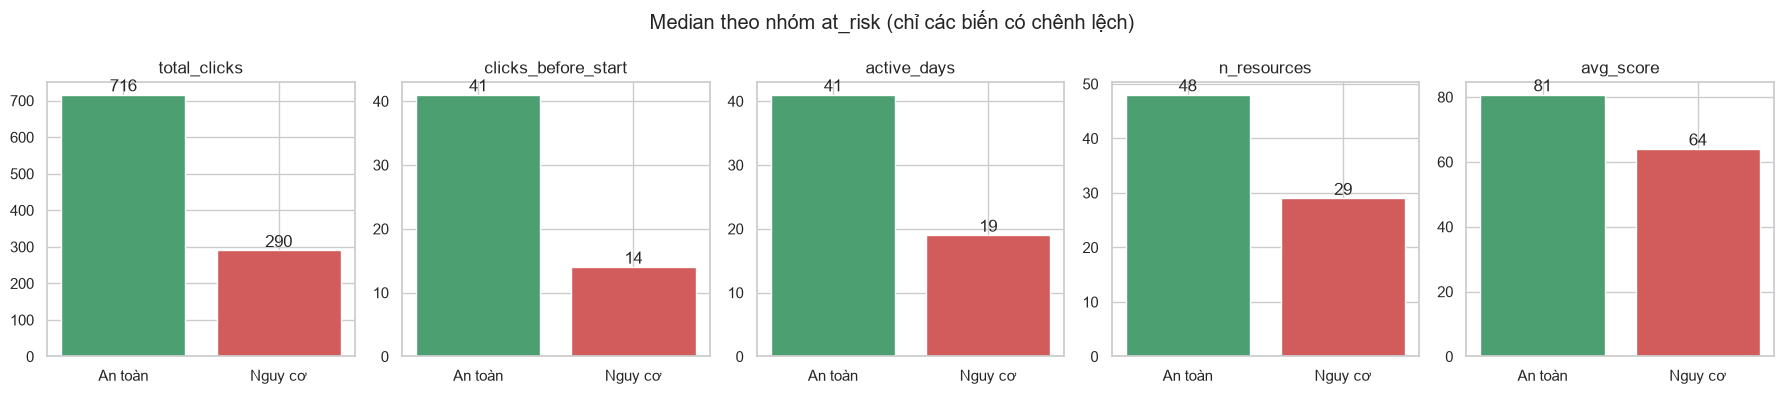

In [21]:
# Chỉ vẽ các biến có chênh lệch median đáng kể giữa hai nhóm (lấy từ bảng `med` ở trên):
# |chênh lệch| >= 5% median lớn hơn. Các biến chênh lệch 0 hoặc gần 0 (date_registration: -1 ngày) bị bỏ qua.
scale = med[['median_an_toan', 'median_nguy_co']].abs().max(axis=1)
show = med.index[(med['chenh_lech'].abs() >= 0.05 * scale) & (scale > 0)]
show = med.loc[show, 'chenh_lech'].abs().sort_values(ascending=False).index

fig, axes = plt.subplots(1, len(show), figsize=(3.6 * len(show), 4))
for ax, c in zip(axes, show):
    m = med.loc[c, ['median_an_toan', 'median_nguy_co']]
    ax.bar(['An toàn', 'Nguy cơ'], m.values, color=['#4C9F70', '#D25C5C'])
    for i, v in enumerate(m.values):
        ax.text(i, v, f'{v:.0f}', ha='center', va='bottom')
    ax.set_title(c)
fig.suptitle('Median theo nhóm at_risk (chỉ các biến có chênh lệch)')
plt.tight_layout(); plt.show()

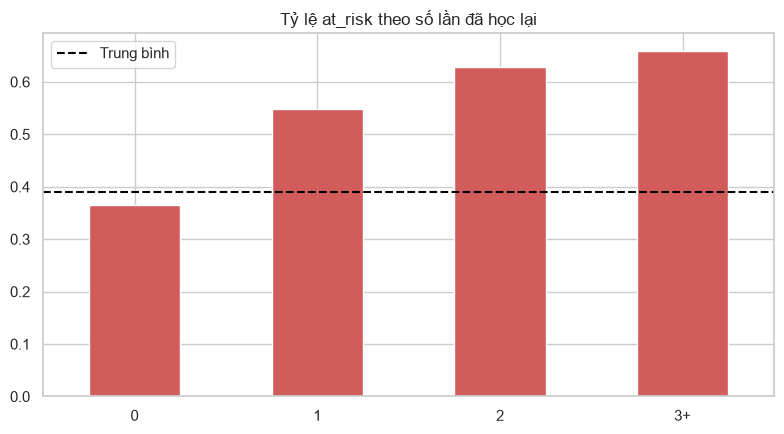

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
rep = df.groupby(df['num_of_prev_attempts'].clip(upper=3))['at_risk'].mean()
rep.index = ['0', '1', '2', '3+']
rep.plot.bar(ax=ax, color='#D25C5C', rot=0)
ax.set_title('Tỷ lệ at_risk theo số lần đã học lại')
line = ax.axhline(df['at_risk'].mean(), color='black', ls='--', label='Trung bình')
ax.legend(handles=[line]); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Nhận xét.**
- Nhóm biến **hoạt động VLE** (`total_clicks`, `active_days`, `n_resources`, `clicks_before_start`) và **điểm** (`avg_score`) chênh lệch rõ nhất giữa hai nhóm: sinh viên nguy cơ click ít hơn khoảng 2,5 lần và điểm thấp hơn khoảng 17 điểm.
- `studied_credits` và `date_registration` có median gần như bằng nhau ở hai nhóm, tức là không phân biệt được nguy cơ. **Hai biến này bị loại khỏi mô hình** ở phần 5.
- Tỷ lệ nguy cơ khác nhau rõ giữa các môn, từ khoảng 22% (AAA) đến 45% (DDD), nên `code_module` được đưa vào mô hình làm biến điều khiển.
- Sinh viên chưa học lại có tỷ lệ nguy cơ khoảng 36%; đã học lại 1 lần tăng vọt lên khoảng 55%, 2 lần trở lên tăng thêm không nhiều (63 – 66%). Bước nhảy lớn nhất là giữa 0 và 1, nên biến này được gộp thành `is_repeater` (0/1) ở phần 4.4.

### 4.3 Phân tích đa biến (tương quan Spearman)

Dùng **Spearman** (tính trên thứ hạng) thay vì Pearson vì dữ liệu lệch mạnh và nhiều outlier. |ρ| ≥ 0.7 giữa hai biến X là dấu hiệu đa cộng tuyến.

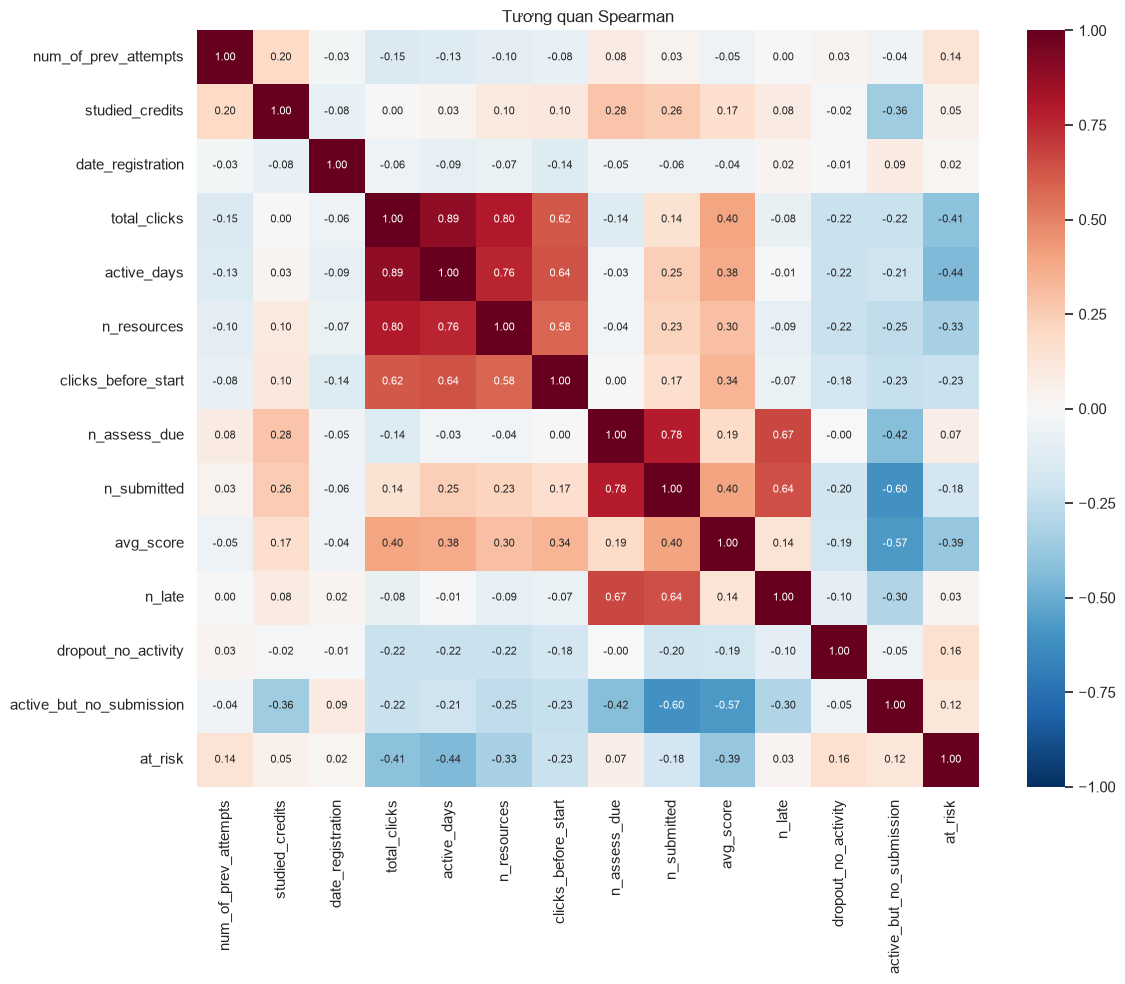

active_days                -0.437719
total_clicks               -0.411149
avg_score                  -0.385177
n_resources                -0.328258
clicks_before_start        -0.225302
n_submitted                -0.180388
date_registration           0.023163
n_late                      0.027647
studied_credits             0.054457
n_assess_due                0.069587
active_but_no_submission    0.117384
num_of_prev_attempts        0.137749
dropout_no_activity         0.159041
Name: at_risk, dtype: float64

In [23]:
corr = df[num + ['dropout_no_activity', 'active_but_no_submission', 'at_risk']].corr(method='spearman')
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Tương quan Spearman'); plt.tight_layout(); plt.show()

corr['at_risk'].drop('at_risk').sort_values()

**Nhận xét.**
- Tương quan âm mạnh nhất với `at_risk`: `active_days`, `total_clicks`, `avg_score`, `n_resources`. Hoạt động càng nhiều, điểm càng cao thì nguy cơ càng thấp.
- Tương quan dương (yếu hơn): `dropout_no_activity`, `num_of_prev_attempts`, `active_but_no_submission`.
- `studied_credits`, `date_registration` gần như không tương quan với `at_risk` (|ρ| < 0.06), khớp với nhận xét ở 4.2.
- Các cặp `total_clicks` – `active_days` – `n_resources` tương quan cao với nhau (ρ ≈ 0.76 – 0.89). Không bỏ biến nào vì chúng đo các khía cạnh khác nhau; thay vào đó tạo biến tỷ số `clicks_per_active_day` (4.4) và dùng ràng buộc L2 mặc định trong Logistic Regression.

### 4.4 Tạo biến mới (Feature Engineering)

Tạo biến trên dữ liệu đã xử lý outlier ở 3.6:

| Biến mới | Công thức | Ý nghĩa |
|---|---|---|
| `n_missed` | `n_assess_due − n_submitted` | Số bài bỏ lỡ, sinh viên không theo kịp lịch. |
| `submission_rate` | `n_submitted / n_assess_due` | Tỷ lệ nộp bài, so sánh được giữa môn ít bài và nhiều bài. |
| `late_rate` | `n_late / n_submitted` | Tỷ lệ nộp trễ. |
| `clicks_per_active_day` | `total_clicks / active_days` | Cường độ học mỗi ngày; tách "học đều" và "học dồn", giảm trùng lặp giữa `total_clicks` và `active_days`. Biến này cũng lệch phải nên được chặn tại P99 như ở 3.6. |
| `is_repeater` | `num_of_prev_attempts > 0` | 87% sinh viên chưa học lại; điểm khác biệt lớn nhất là có/không học lại, không phải số lần. |

Phép chia cho 0 (chưa có bài đến hạn / chưa nộp / chưa hoạt động) được gán bằng 0.

In [24]:
fe['n_missed']              = fe['n_assess_due'] - fe['n_submitted']
fe['submission_rate']       = (fe['n_submitted'] / fe['n_assess_due']).fillna(0)
fe['late_rate']             = (fe['n_late'] / fe['n_submitted']).fillna(0)
fe['clicks_per_active_day'] = (fe['total_clicks'] / fe['active_days']).fillna(0)
fe['clicks_per_active_day'] = fe['clicks_per_active_day'].clip(upper=fe['clicks_per_active_day'].quantile(.99))
fe['is_repeater']           = (fe['num_of_prev_attempts'] > 0).astype(int)

NEW = ['n_missed', 'submission_rate', 'late_rate', 'clicks_per_active_day', 'is_repeater']
fe[NEW].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
n_missed,25219.0,0.27,0.74,0.0,0.00,0.00,0.0,6.00
submission_rate,25219.0,0.81,0.36,0.0,0.83,1.00,1.0,1.00
late_rate,25219.0,0.24,0.33,0.0,0.00,0.00,0.5,1.00
clicks_per_active_day,25219.0,19.03,10.66,0.0,11.79,16.94,24.2,57.63
is_repeater,25219.0,0.13,0.33,0.0,0.00,0.00,0.0,1.00


**Kiểm tra đa cộng tuyến bằng VIF** trên tập biến số cuối cùng sẽ đưa vào mô hình. VIF = 1 / (1 − R²), với R² là mức một biến được dự đoán bởi các biến còn lại. VIF < 5: an toàn; 5 – 10: cảnh báo; > 10: trùng lặp mạnh.

In [25]:
from sklearn.linear_model import LinearRegression

FEATURES_NUM = ['log_total_clicks', 'active_days', 'n_resources', 'log_clicks_before_start',
                'n_assess_due', 'n_submitted', 'avg_score', 'n_late',
                'n_missed', 'submission_rate', 'late_rate', 'clicks_per_active_day',
                'is_repeater', 'dropout_no_activity', 'active_but_no_submission']

def vif(X):
    return pd.Series({c: 1 / (1 - LinearRegression().fit(X.drop(columns=c), X[c])
                                   .score(X.drop(columns=c), X[c]))
                      for c in X.columns}).sort_values(ascending=False).round(2)

vif(fe[FEATURES_NUM].drop(columns='n_assess_due'))

n_late                      14.96
submission_rate             13.28
active_but_no_submission    12.73
late_rate                    9.00
log_total_clicks             8.91
n_submitted                  8.67
avg_score                    5.71
active_days                  4.47
dropout_no_activity          3.42
n_resources                  3.02
clicks_per_active_day        2.55
n_missed                     2.34
log_clicks_before_start      1.81
is_repeater                  1.06
dtype: float64

**Nhận xét.** `n_assess_due` không đưa vào VIF vì `n_missed = n_assess_due − n_submitted` là quan hệ tuyến tính chính xác (VIF vô hạn). Các biến VIF cao (`n_late`, `submission_rate`, `active_but_no_submission`) đều được tạo trực tiếp từ các biến khác nên trùng lặp là đương nhiên. Vẫn giữ lại vì:
- Random Forest không bị ảnh hưởng bởi đa cộng tuyến.
- Logistic Regression dùng ràng buộc L2 (mặc định của `sklearn`) giữ các hệ số nhỏ và ổn định.

Xuất bảng đặc trưng cuối cùng ra `data/eda/features.csv` để dùng cho Part 5.

In [26]:
fe.to_csv('data/eda/features.csv', index=False)
print(fe.shape)

(25219, 28)


# PART 5: MÔ HÌNH & ĐÁNH GIÁ

### 5.1 Chia dữ liệu: train / validation / test = 70 / 15 / 15

Chia ngẫu nhiên có phân tầng theo `at_risk` (`stratify`) để cả ba tập giữ cùng tỷ lệ nguy cơ khoảng 39%:
- **Train (70%)**: huấn luyện mô hình.
- **Validation (15%)**: so sánh các bộ siêu tham số khi tinh chỉnh (5.4) và chọn ngưỡng dự đoán (5.5).
- **Test (15%)**: chỉ dùng để báo cáo kết quả, không dùng để chọn bất cứ thứ gì.

Biến đưa vào mô hình: 15 biến số (`FEATURES_NUM` ở 4.4) + 2 biến phân loại (`code_module`, `pres_semester`). Loại bỏ: `id_student`, `final_result` (nguồn target), `cutoff_day`, `code_presentation`, `num_of_prev_attempts` (đã thành `is_repeater`), `total_clicks` và `clicks_before_start` (đã thay bằng bản log), `studied_credits` và `date_registration` (không phân biệt được nguy cơ, xem 4.2).

In [27]:
from sklearn.model_selection import train_test_split

FEATURES_CAT = ['code_module', 'pres_semester']
FEATURES = FEATURES_NUM + FEATURES_CAT

train, rest = train_test_split(fe, test_size=0.30, stratify=fe['at_risk'], random_state=RNG)
val, test   = train_test_split(rest, test_size=0.50, stratify=rest['at_risk'], random_state=RNG)

X_train, y_train = train[FEATURES], train['at_risk']
X_val,   y_val   = val[FEATURES],   val['at_risk']
X_test,  y_test  = test[FEATURES],  test['at_risk']

for name, y in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name:10s}: {len(y):6,} dòng ({len(y) / len(fe):.0%}), at_risk = {y.mean():.3f}')

Train     : 17,653 dòng (70%), at_risk = 0.390
Validation:  3,783 dòng (15%), at_risk = 0.390
Test      :  3,783 dòng (15%), at_risk = 0.390


### 5.2 Pipeline + 2 mô hình baseline

`ColumnTransformer` chuẩn hoá biến số (`StandardScaler`) và one-hot biến phân loại; chỉ fit trên train nên không rò rỉ thông tin sang validation và test. Ở bước này hai mô hình dùng **siêu tham số mặc định** của `sklearn`:
- **Logistic Regression**: mô hình tuyến tính, có ràng buộc L2, dễ diễn giải qua hệ số.
- **Random Forest**: phi tuyến, bắt được tương tác giữa các biến.

Cả hai dùng `class_weight='balanced'` để phạt việc bỏ sót sinh viên nguy cơ nặng hơn.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

prep = ColumnTransformer([
    ('num', StandardScaler(), FEATURES_NUM),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), FEATURES_CAT),
])

def make_lr(**params):
    return make_pipeline(prep, LogisticRegression(class_weight='balanced', max_iter=2000,
                                                  random_state=RNG, **params))

def make_rf(**params):
    return make_pipeline(prep, RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                                      random_state=RNG, **params))

baseline = {'Logistic Regression': make_lr(), 'Random Forest': make_rf()}
for m in baseline.values():
    m.fit(X_train, y_train)

### 5.3 Đánh giá baseline trên tập test (ngưỡng 0.5)

In [29]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

def evaluate(models, X, y, threshold=0.5):
    rows = []
    for name, m in models.items():
        ypp = m.predict_proba(X)[:, 1]
        yp = (ypp >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, yp).ravel()
        rows.append({'model': name,
                     'accuracy': accuracy_score(y, yp),
                     'precision': precision_score(y, yp),
                     'recall': recall_score(y, yp),
                     'f1': f1_score(y, yp),
                     'roc_auc': roc_auc_score(y, ypp),
                     'pr_auc': average_precision_score(y, ypp),
                     'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
    return pd.DataFrame(rows).set_index('model').round(4)

evaluate(baseline, X_test, y_test)

,accuracy,precision,recall,f1,roc_auc,pr_auc,TN,FP,FN,TP
model,,,,,,,,,,
Logistic Regression,0.7846,0.7203,0.7315,0.7259,0.8569,0.8240,1889,419,396,1079
Random Forest,0.7883,0.7340,0.7166,0.7252,0.8591,0.8255,1925,383,418,1057


### 5.4 Tinh chỉnh siêu tham số (Fine-tuning)

Thử một lưới nhỏ siêu tham số. Mỗi bộ được huấn luyện trên **train** và chấm điểm bằng **F1 trên validation ở ngưỡng 0.3** (dự đoán "nguy cơ" khi xác suất ≥ 0.3, ưu tiên không bỏ sót sinh viên nguy cơ); bộ có F1 cao nhất được chọn. Tập test không tham gia vào việc chọn.

| Mô hình | Siêu tham số | Giá trị thử | Ý nghĩa |
|---|---|---|---|
| Logistic Regression | `C` | 0.01, 0.1, 1, 10 | Nghịch đảo độ mạnh ràng buộc L2; `C` càng nhỏ thì hệ số càng bị kéo về 0. |
| Random Forest | `max_depth` | None, 10, 20 | Độ sâu tối đa của mỗi cây. |
| Random Forest | `min_samples_leaf` | 1, 5, 20 | Số mẫu tối thiểu ở mỗi lá; càng lớn thì cây càng ít khớp nhiễu. |

Random Forest dùng cố định `n_estimators = 300`.

In [30]:
from itertools import product

THRESHOLD = 0.5

grid = {'Logistic Regression': (make_lr, [dict(C=c) for c in [0.01, 0.1, 1, 10]]),
        'Random Forest': (make_rf, [dict(n_estimators=300, max_depth=d, min_samples_leaf=l)
                                    for d, l in product([None, 10, 20], [1, 5, 20])])}

rows, tuned = [], {}
for name, (build, params_list) in grid.items():
    best_f1 = -1
    for params in params_list:
        m = build(**params).fit(X_train, y_train)
        f1 = f1_score(y_val, m.predict_proba(X_val)[:, 1] >= THRESHOLD)
        label = ', '.join(f'{k}={v}' for k, v in params.items() if k != 'n_estimators')
        rows.append({'model': name, 'params': label, 'val_f1': round(f1, 4)})
        if f1 > best_f1:
            best_f1, tuned[name] = f1, m

tuning = pd.DataFrame(rows).sort_values(['model', 'val_f1'], ascending=[True, False])
tuning.groupby('model').head(3)   # 3 bộ tốt nhất của mỗi mô hình

,model,params,val_f1
2,Logistic Regression,C=1,0.7074
3,Logistic Regression,C=10,0.7068
1,Logistic Regression,C=0.1,0.7033
5,Random Forest,"max_depth=None, min_samples_leaf=5",0.7115
9,Random Forest,"max_depth=10, min_samples_leaf=20",0.7114
11,Random Forest,"max_depth=20, min_samples_leaf=5",0.7110


**So sánh trước và sau tinh chỉnh trên tập test (ngưỡng 0.3).**

In [31]:
compare = pd.concat({'Baseline': evaluate(baseline, X_test, y_test, THRESHOLD),
                     'Sau tinh chỉnh': evaluate(tuned, X_test, y_test, THRESHOLD)}, names=['phien_ban'])
compare.swaplevel().sort_index()

accuracy  precision  recall      f1  \
model               phien_ban                                             
Logistic Regression Baseline          0.7846     0.7203  0.7315  0.7259   
                    Sau tinh chỉnh    0.7846     0.7203  0.7315  0.7259   
Random Forest       Baseline          0.7883     0.7340  0.7166  0.7252   
                    Sau tinh chỉnh    0.7936     0.7348  0.7363  0.7355   

                                    roc_auc  pr_auc    TN   FP   FN    TP  
model               phien_ban                                              
Logistic Regression Baseline         0.8569  0.8240  1889  419  396  1079  
                    Sau tinh chỉnh   0.8569  0.8240  1889  419  396  1079  
Random Forest       Baseline         0.8591  0.8255  1925  383  418  1057  
                    Sau tinh chỉnh   0.8653  0.8363  1916  392  389  1086

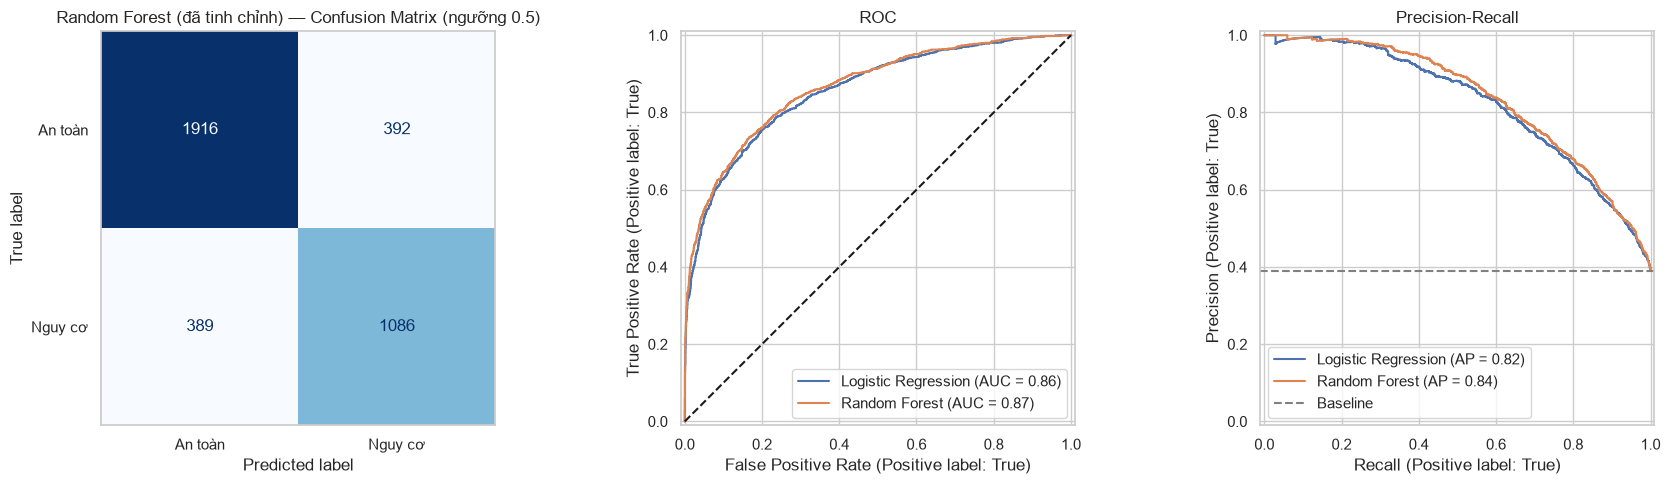

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, m in tuned.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[2])
ConfusionMatrixDisplay.from_predictions(y_test, tuned['Random Forest'].predict_proba(X_test)[:, 1] >= THRESHOLD,
                                      display_labels=['An toàn', 'Nguy cơ'], cmap='Blues',
                                      colorbar=False, ax=axes[0])
axes[0].set_title(f'Random Forest (đã tinh chỉnh) — Confusion Matrix (ngưỡng {THRESHOLD})'); axes[0].grid(False)
axes[1].plot([0, 1], [0, 1], 'k--'); axes[1].set_title('ROC')
axes[2].axhline(y_test.mean(), ls='--', color='gray', label='Baseline')
axes[2].set_title('Precision-Recall'); axes[2].legend()
plt.tight_layout(); plt.show()

**Nhận xét.**
- Ở ngưỡng 0.3, cả hai mô hình đổi Precision lấy Recall: so với ngưỡng 0.5 (5.3), Recall trên test tăng lên khoảng 0.87–0.88 nhưng Precision giảm còn khoảng 0.57–0.59. Số sinh viên nguy cơ bị bỏ sót (FN) giảm từ khoảng 400 xuống dưới 200, đổi lại số cảnh báo nhầm (FP) tăng lên khoảng 900–1.000.
- **Logistic Regression** gần như không đổi: bộ tốt nhất là `C = 10`, F1 trên validation chỉ hơn mặc định (`C = 1`) 0.0006; trên test F1 từ 0.693 lên 0.694. Với khoảng 17.600 dòng train và 17 biến, độ mạnh của ràng buộc L2 ít ảnh hưởng tới mô hình.
- **Random Forest** cải thiện nhẹ: bộ tốt nhất là `max_depth = None`, `min_samples_leaf = 1`, tức giữ cấu trúc cây mặc định và chỉ tăng số cây từ 100 lên 300. Trên test, F1 tăng từ 0.703 lên 0.708, Recall từ 0.867 lên 0.875, PR-AUC từ 0.826 lên 0.830; FN giảm từ 196 xuống 185. Mức tăng nhỏ, chủ yếu do nhiều cây hơn làm xác suất dự đoán ổn định hơn. Ở ngưỡng 0.3, các bộ giới hạn lá (`min_samples_leaf = 5, 20`) không cho F1 trên validation cao hơn.
- Sau tinh chỉnh, Random Forest tốt hơn Logistic Regression ở Accuracy, Precision, F1, ROC-AUC, PR-AUC và ít cảnh báo nhầm hơn (881 so với 978), chỉ có Recall thấp hơn một chút (0.875 so với 0.884). Vì vậy **Random Forest đã tinh chỉnh** được chọn làm mô hình cuối.

### 5.5 Chọn ngưỡng dự đoán

Ngưỡng 0.5 chưa chắc là tốt nhất. Hạ ngưỡng sẽ bắt được nhiều sinh viên nguy cơ hơn (Recall tăng) nhưng nhiều cảnh báo nhầm hơn (Precision giảm). Ngưỡng được xem xét trên **validation**, sau đó kiểm tra lại trên test.

In [33]:
final = tuned['Random Forest']
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    row = {'threshold': t}
    for split, X, y in [('val', X_val, y_val), ('test', X_test, y_test)]:
        pred = final.predict_proba(X)[:, 1] >= t
        row[f'precision_{split}'] = precision_score(y, pred)
        row[f'recall_{split}'] = recall_score(y, pred)
    rows.append(row)
pd.DataFrame(rows).round(3)

,threshold,precision_val,recall_val,precision_test,recall_test
0,0.3,0.577,0.870,0.577,0.892
1,0.4,0.648,0.792,0.658,0.828
2,0.5,0.732,0.692,0.735,0.736
3,0.6,0.814,0.589,0.809,0.639


**Nhận xét.**
- Trên validation, ngưỡng 0.3 cho Recall 0.85 với Precision 0.59. Nâng lên 0.4 thì Recall giảm còn 0.76, Precision tăng lên 0.66; ở 0.5 Recall chỉ còn 0.67.
- Trên test, xu hướng tương tự (ngưỡng 0.3: Recall 0.87, Precision 0.59; ngưỡng 0.4: Recall 0.80, Precision 0.66), cho thấy lựa chọn ngưỡng không chỉ khớp riêng với tập validation.
- Giữ ngưỡng **0.3** như ở 5.4 khi mục tiêu là bắt được nhiều sinh viên nguy cơ nhất; nếu nguồn lực tư vấn hạn chế thì có thể nâng lên 0.4 để giảm cảnh báo nhầm.

### 5.6 Kết luận

**Câu hỏi 1.** Mức độ tương tác trên VLE (`active_days`, `total_clicks`, `n_resources`, `clicks_before_start`) và điểm các bài đã làm (`avg_score`) là những yếu tố dự báo mạnh nhất. Sinh viên không nộp bài và không vào VLE trước mốc cảnh báo gần như chắc chắn trượt hoặc rút (99%). Số tín chỉ và ngày đăng ký gần như không có tác dụng dự báo.

**Câu hỏi 2.** Chọn **Random Forest đã tinh chỉnh** (300 cây, `min_samples_leaf = 1`) với ngưỡng **0.3** làm mô hình chính: trên test đạt Recall 0.87, F1 0.71, ROC-AUC 0.86, PR-AUC 0.83, tốt hơn Logistic Regression ở F1, Precision, ROC-AUC và PR-AUC, Recall chỉ thấp hơn khoảng 0.01. Logistic Regression vẫn hữu ích để kiểm tra chéo và diễn giải qua hệ số. Nếu nguồn lực tư vấn ít thì nâng ngưỡng lên **0.4** (Recall 0.80, Precision 0.67 trên test) hoặc 0.5 để giảm cảnh báo nhầm.

**Hạn chế.**
1. Chỉ có 4 kỳ dữ liệu, chưa bắt được xu hướng dài hạn.
2. Xác suất `predict_proba` chưa được hiệu chuẩn (calibration) nên chưa dùng trực tiếp làm "xác suất rủi ro".
3. Chưa kiểm tra công bằng theo nhóm sinh viên (fairness audit).
4. Ngưỡng P99 khi chặn outlier được tính trên toàn bộ dữ liệu trước khi chia train/validation/test.
5. Dữ liệu được chia ngẫu nhiên nên cả ba tập đều chứa sinh viên của cùng các kỳ học. Kết quả chưa phản ánh tình huống dùng mô hình học từ các kỳ cũ để dự đoán một kỳ mới hoàn toàn; muốn kiểm tra điều đó cần chia theo thời gian.
6. Lưới tinh chỉnh còn nhỏ (4 bộ cho Logistic Regression, 9 bộ cho Random Forest).